# 01 - Analyse Exploratoire des Données (EDA) & Contrôle Qualité

**Objectif :** Examiner l'intégrité du dataset historique, caractériser la distribution de la cible `count`, analyser l'impact des facteurs temporels et météorologiques sur la demande de vélos, et valider formellement les règles d'exclusion de variables pour prévenir toute fuite de données (Data Leakage).

## Dictionnaire des colonnes

*(Source officielle : Page de description de la compétition Kaggle Bike Sharing Demand)*

| Colonne | Signification | Remarque |
| :--- | :--- | :--- |
| `datetime` | Date et heure | À convertir en datetime |
| `season` | Saison | 1 = printemps, 2 = été, 3 = automne, 4 = hiver |
| `holiday` | Jour férié (0/1) | |
| `workingday` | Jour travaillé (0/1) | Ni week-end ni férié |
| `weather` | Météo | 1 = beau, 2 = brouillard/nuages, 3 = neige/pluie légère, 4 = pluie forte/orage |
| `temp` | Température réelle (°C) | |
| `atemp` | Température ressentie (°C) | Très corrélée à temp |
| `humidity` | Humidité (%) | |
| `windspeed` | Vitesse du vent | Beaucoup de zéros suspects |
| `casual` | Locations par les non-abonnés | Fuite si utilisée comme entrée |
| `registered` | Locations par les abonnés | Fuite si utilisée comme entrée |
| `count` | Total des locations (casual + registered) | Cible |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration graphique propre
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

---
## Bloc A : Contrôle d'intégrité

### Question :
Le fichier est-il complet, et les types sont-ils corrects ?

In [2]:
# Chargement des données brutes
df = pd.read_csv('../data/raw/train.csv')

print('1. Volumétrie (lignes, colonnes) :', df.shape)
print('\n2. Types initiaux :\n', df.dtypes)
print('\n3. Nombre total de valeurs manquantes :', df.isna().sum().sum())
print('4. Nombre de doublons parfaits :', df.duplicated().sum())

# Conversion de datetime
df['datetime'] = pd.to_datetime(df['datetime'])
print('\n5. Type après conversion :', df['datetime'].dtype)
print('6. Plage temporelle : du', df['datetime'].min(), 'au', df['datetime'].max())

1. Volumétrie (lignes, colonnes) : (10886, 12)

2. Types initiaux :
 datetime       object
season          int64
holiday         int64
workingday      int64
weather         int64
temp          float64
atemp         float64
humidity        int64
windspeed     float64
casual          int64
registered      int64
count           int64
dtype: object

3. Nombre total de valeurs manquantes : 0
4. Nombre de doublons parfaits : 0

5. Type après conversion : datetime64[ns]
6. Plage temporelle : du 2011-01-01 00:00:00 au 2012-12-19 23:00:00


### Constat :
- **Volumétrie** : Exactement 10 886 lignes et 12 colonnes, conforme au dataset officiel Kaggle.
- **Valeurs manquantes & doublons** : 0 valeur manquante (`NaN`) et 0 ligne dupliquée dans tout le fichier.
- **Typage & Plage** : La colonne `datetime` est convertie en type `datetime64[ns]`. La plage s'étend du 01/01/2011 00:00:00 au 19/12/2012 23:00:00 (les 19 premiers jours de chaque mois).

---
## Bloc B : Analyse de la cible count

### Question :
La distribution est-elle symétrique, et quelles valeurs extrêmes contient-elle ?

Statistiques descriptives de 'count' :
count    10886.000000
mean       191.574132
std        181.144454
min          1.000000
25%         42.000000
50%        145.000000
75%        284.000000
max        977.000000
Name: count, dtype: float64

1. Skewness count brut          : 1.2421
2. Skewness sqrt(count)         : 0.2576
3. Skewness log1p(count)        : -0.8514


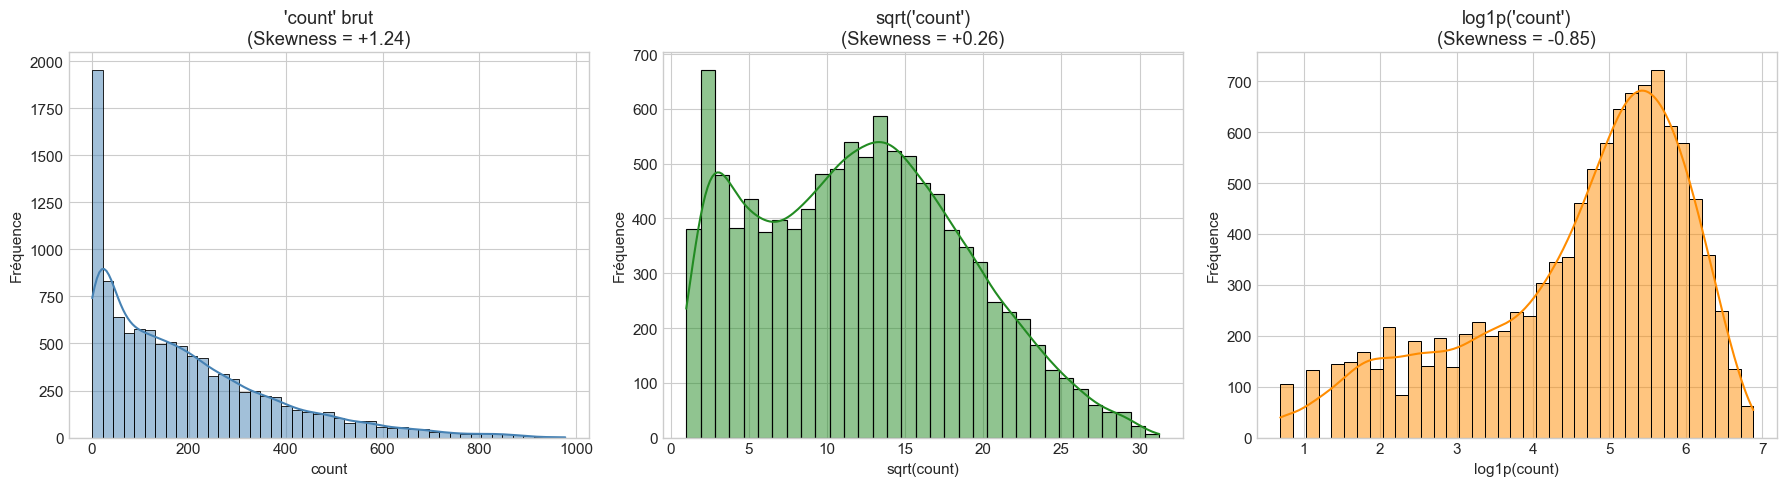

In [3]:
print("Statistiques descriptives de 'count' :")
print(df['count'].describe())

skew_raw = df['count'].skew()
skew_sqrt = np.sqrt(df['count']).skew()
skew_log = np.log1p(df['count']).skew()

print(f"\n1. Skewness count brut          : {skew_raw:.4f}")
print(f"2. Skewness sqrt(count)         : {skew_sqrt:.4f}")
print(f"3. Skewness log1p(count)        : {skew_log:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Count brut
sns.histplot(df['count'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title(f"'count' brut\n(Skewness = {skew_raw:+.2f})")
axes[0].set_xlabel("count")
axes[0].set_ylabel("Fréquence")

# 2. sqrt(count)
sns.histplot(np.sqrt(df['count']), kde=True, ax=axes[1], color='forestgreen')
axes[1].set_title(f"sqrt('count')\n(Skewness = {skew_sqrt:+.2f})")
axes[1].set_xlabel("sqrt(count)")
axes[1].set_ylabel("Fréquence")

# 3. log1p(count)
sns.histplot(np.log1p(df['count']), kde=True, ax=axes[2], color='darkorange')
axes[2].set_title(f"log1p('count')\n(Skewness = {skew_log:+.2f})")
axes[2].set_xlabel("log1p(count)")
axes[2].set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

### Constat :
- **Distribution brute** : Très étirée vers la droite (asymétrique positive, skewness de **+1.2421**). La médiane (145.0) est nettement inférieure à la moyenne (191.57), avec une valeur maximale de 977 locations/h.
- **Comparaison des transformations de stabilisation** :
  - **`sqrt(count)`** : Skewness ramené à **+0.2576**. Cette transformation produit une distribution quasi-symétrique (proche de 0), mais laisse apparaître une légère bimodalité résiduelle (liée aux deux modes de consommation urbaine mis en évidence au Bloc C : heures creuses nocturnes vs heures de pointe domicile-travail).
  - **`log1p(count)`** : Skewness de **-0.8514** (sur-correction induisant une asymétrie vers la gauche, non symétrique).
- **Décision technique & Restitution** :
  1. `log1p(count)` et `sqrt(count)` sont retenues comme deux **variantes candidates**. Le choix final ne se fera pas sur le seul critère de skewness, mais sera **départagé en J3/J4 par l'évaluation des erreurs réelles après ré-inversion**.
  2. **Distinction entre perte d'entraînement et métriques finales** : la fonction de coût minimisée sur données transformées ne doit pas être confondue avec la performance métier. Les prédictions seront obligatoirement ré-inversées sur l'échelle réelle (ex: `expm1(y_pred)` ou `(y_pred)**2` écrêté à $\ge 0$).
  3. **Restitution à double niveau** : nous reporterons le **RMSE et MAE sur l'échelle réelle (en nombre de vélos)** pour le dimensionnement opérationnel et Power BI, et le **RMSLE** séparément pour la validation mathématique.

---
## Bloc C : Analyse des variables explicatives

### Question :
Quels facteurs font varier la demande ?

Moyenne à 8h  : Jour ouvré = 479.95 | Non-ouvré = 112.26
Moyenne à 17h : Jour ouvré = 529.21 | Non-ouvré = 339.12
Heure de pointe globale absolue : 17h (468.77 vélos/h)


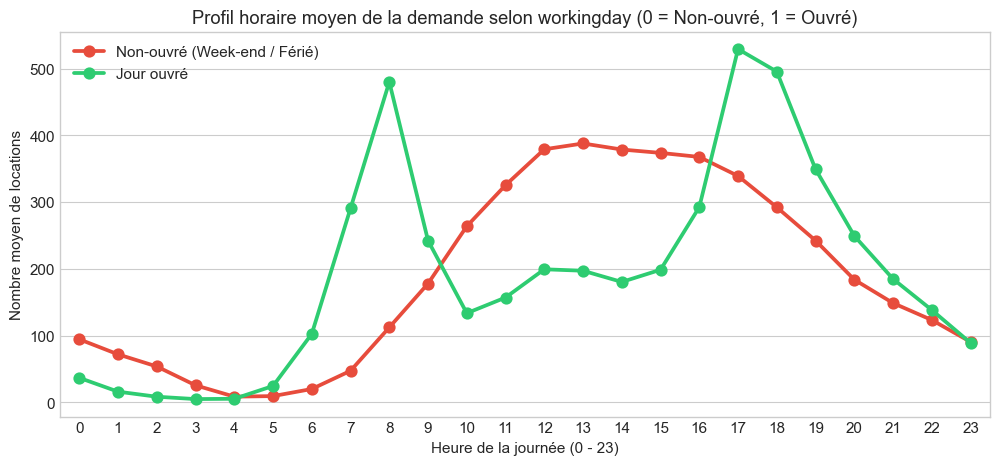

In [4]:
# Extraction temporelle descriptive
df['hour'] = df['datetime'].dt.hour
df['month'] = df['datetime'].dt.month

# Calculs précis de référence
h8_work1 = df[(df['hour'] == 8) & (df['workingday'] == 1)]['count'].mean()
h8_work0 = df[(df['hour'] == 8) & (df['workingday'] == 0)]['count'].mean()
h17_work1 = df[(df['hour'] == 17) & (df['workingday'] == 1)]['count'].mean()
h17_work0 = df[(df['hour'] == 17) & (df['workingday'] == 0)]['count'].mean()

print(f"Moyenne à 8h  : Jour ouvré = {h8_work1:.2f} | Non-ouvré = {h8_work0:.2f}")
print(f"Moyenne à 17h : Jour ouvré = {h17_work1:.2f} | Non-ouvré = {h17_work0:.2f}")
print(f"Heure de pointe globale absolue : {df.groupby('hour')['count'].mean().idxmax()}h ({df.groupby('hour')['count'].mean().max():.2f} vélos/h)")

# Graphique 1 : Profil horaire selon le type de jour
plt.figure(figsize=(12, 5))
sns.pointplot(data=df, x='hour', y='count', hue='workingday', errorbar=None, palette=['#e74c3c', '#2ecc71'])
plt.title("Profil horaire moyen de la demande selon workingday (0 = Non-ouvré, 1 = Ouvré)")
plt.xlabel("Heure de la journée (0 - 23)")
plt.ylabel("Nombre moyen de locations")
plt.legend(['Non-ouvré (Week-end / Férié)', 'Jour ouvré'])
plt.show()

### Constat (Profil horaire & Calendrier) :
- **Chiffres exacts** :
  - À 8h00 : **479.95** vélos/h en jour ouvré contre **112.26** en jour non-ouvré.
  - À 17h00 : **529.21** vélos/h en jour ouvré contre **339.12** en jour non-ouvré.
  - L'heure de pointe absolue tous jours confondus est **17h00** (**468.77** vélos/h en moyenne), suivie de 18h00 (430.86 vélos/h).
- **Conclusion sur l'hypothèse** : **Hypothèse confirmée**. La demande horaire est conditionnée par l'activité : profil bimodal de déplacements pendulaires domicile-travail en semaine vs profil unimodal de loisirs l'après-midi les week-ends/fériés.

Moyennes par saison :
 season
1    116.34
2    215.25
3    234.42
4    198.99
Name: count, dtype: float64

Statistiques par météo (moyenne et effectif) :
            mean  count
weather               
1        205.24   7192
2        178.96   2834
3        118.85    859
4        164.00      1


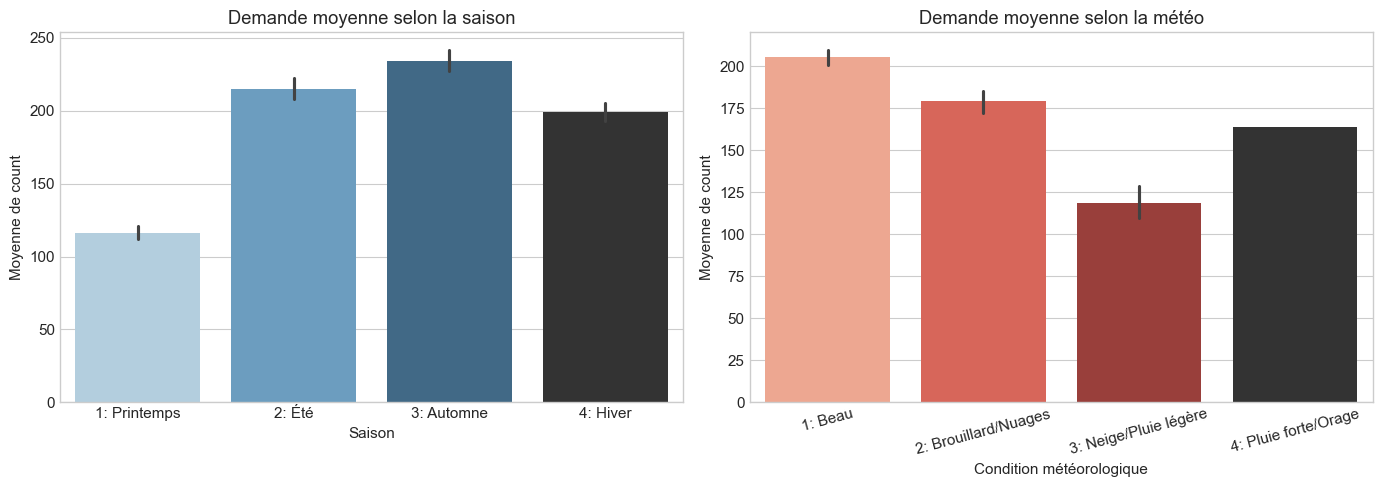

In [5]:
# Calculs exacts par saison et météo
season_means = df.groupby('season')['count'].mean()
weather_stats = df.groupby('weather')['count'].agg(['mean', 'count'])

print("Moyennes par saison :\n", season_means.round(2))
print("\nStatistiques par météo (moyenne et effectif) :\n", weather_stats.round(2))

# Graphique 2 : Saison et Météo (Code corrigé sans warning)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

season_labels = ['1: Printemps', '2: Été', '3: Automne', '4: Hiver']
weather_labels = ['1: Beau', '2: Brouillard/Nuages', '3: Neige/Pluie légère', '4: Pluie forte/Orage']

sns.barplot(data=df, x='season', y='count', hue='season', legend=False, ax=axes[0], palette='Blues_d')
axes[0].set_xticks(range(len(season_labels)))
axes[0].set_xticklabels(season_labels)
axes[0].set_title("Demande moyenne selon la saison")
axes[0].set_xlabel("Saison")
axes[0].set_ylabel("Moyenne de count")

sns.barplot(data=df, x='weather', y='count', hue='weather', legend=False, ax=axes[1], palette='Reds_d')
axes[1].set_xticks(range(len(weather_labels)))
axes[1].set_xticklabels(weather_labels, rotation=15)
axes[1].set_title("Demande moyenne selon la météo")
axes[1].set_xlabel("Condition météorologique")
axes[1].set_ylabel("Moyenne de count")

plt.tight_layout()
plt.show()

### Constat (Saison & Conditions météorologiques) :
- **Saisons (chiffres réels vérifiés)** :
  - 1 (Printemps) : **116.34** vélos/h
  - 2 (Été) : **215.25** vélos/h
  - 3 (Automne) : **234.42** vélos/h
  - 4 (Hiver) : **198.99** vélos/h
  - *Conclusion sur l'hypothèse* : **Hypothèse confirmée**. Le printemps est nettement en retrait, tandis que l'été, l'automne et l'hiver maintiennent des volumes élevés proches de 200 à 235 vélos/h.
- **Météo (source officielle Kaggle)** :
  - 1 (Beau) : **205.24** vélos/h (7 192 observations)
  - 2 (Brouillard/Nuages) : **178.96** vélos/h (2 834 observations)
  - 3 (Neige/Pluie légère) : **118.85** vélos/h (859 observations)
  - 4 (Pluie forte/Orage) : **164.00** vélos/h (**exactement 1 seule observation** dans tout le jeu d'entraînement, ce qui explique l'absence de barre d'erreur).
  - *Conclusion sur l'hypothèse* : **Hypothèse partiellement confirmée**. La dégradation des conditions ordinaires (1 -> 2 -> 3) réduit significativement les locations. La catégorie 4 est un cas extrême ultra-minoritaire non représentatif statistiquement.

Corrélation temp / atemp       : 0.9849
Corrélation humidity / count   : -0.3174
Zéros dans windspeed           : 1313 (12.06% des données)


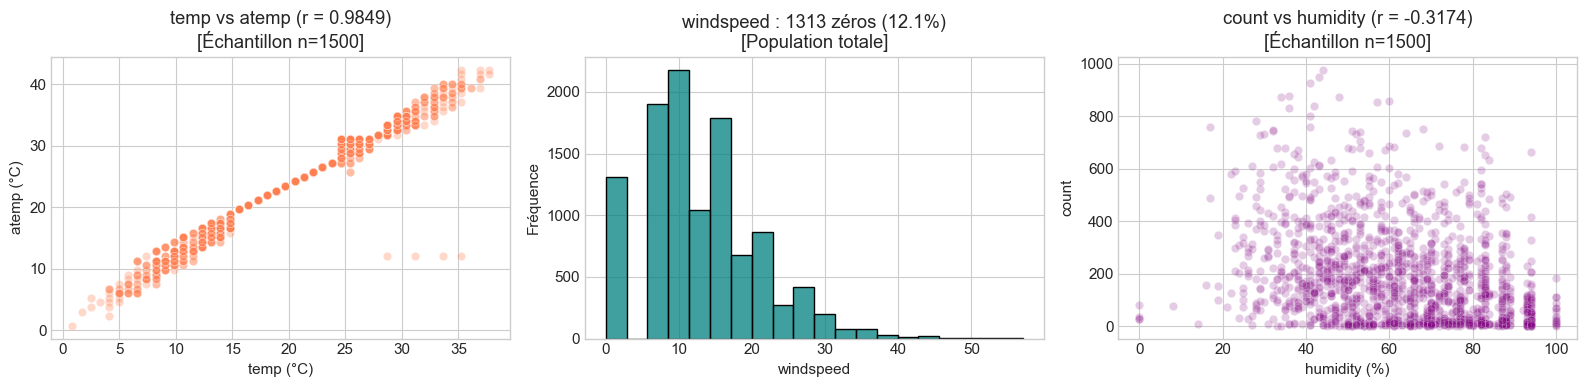

In [6]:
# Calculs de corrélations et comptages d'anomalies
corr_temp_atemp = df[['temp', 'atemp']].corr().iloc[0, 1]
corr_humidity = df['humidity'].corr(df['count'])
zero_wind_n = int((df['windspeed'] == 0).sum())
zero_wind_pct = float((df['windspeed'] == 0).mean() * 100)

print(f"Corrélation temp / atemp       : {corr_temp_atemp:.4f}")
print(f"Corrélation humidity / count   : {corr_humidity:.4f}")
print(f"Zéros dans windspeed           : {zero_wind_n} ({zero_wind_pct:.2f}% des données)")

# Graphique 3 : Variables continues (échantillon de 1 500 observations pour la lisibilité)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.scatterplot(data=df.sample(1500, random_state=42), x='temp', y='atemp', alpha=0.3, ax=axes[0], color='coral')
axes[0].set_title(f"temp vs atemp (r = {corr_temp_atemp:.4f})\n[Échantillon n=1500]")
axes[0].set_xlabel("temp (°C)")
axes[0].set_ylabel("atemp (°C)")

sns.histplot(df['windspeed'], bins=20, ax=axes[1], color='teal')
axes[1].set_title(f"windspeed : {zero_wind_n} zéros ({zero_wind_pct:.1f}%)\n[Population totale]")
axes[1].set_xlabel("windspeed")
axes[1].set_ylabel("Fréquence")

sns.scatterplot(data=df.sample(1500, random_state=42), x='humidity', y='count', alpha=0.2, ax=axes[2], color='purple')
axes[2].set_title(f"count vs humidity (r = {corr_humidity:.4f})\n[Échantillon n=1500]")
axes[2].set_xlabel("humidity (%)")
axes[2].set_ylabel("count")

plt.tight_layout()
plt.show()

### Constat (Variables continues & Anomalies détectées) :
- **Colinéarité `temp` / `atemp`** : Corrélation de Pearson mesurée à **0.9849**. L'hypothèse de quasi-redondance est **confirmée**. Retenir les deux variables est inutile ; nous privilégierons `temp`.
- **Zéros de `windspeed`** : Exactement **1 313 lignes (12.06%)** sont à 0.0. Hypothèse à confirmer : il s'agit très probablement de valeurs non mesurées ou sous le seuil de sensibilité des capteurs, codées par convention à 0.0. La stratégie de traitement est différée au feature engineering (J4) et n'est pas tranchée ici.
- **Humidité** : Le calcul donne une corrélation linéaire de **-0.3174**. L'hypothèse d'un frein à la demande est **confirmée** : il existe une relation négative modérée (l'inconfort lié à l'humidité diminue les locations).

---
## Bloc D : Règle d'exclusion

### Question :
`casual` + `registered` égale-t-il `count` pour toutes les lignes ?

In [7]:
is_exact_sum = (df['casual'] + df['registered'] == df['count']).all()
mismatch_count = (df['casual'] + df['registered'] != df['count']).sum()

print(f"(df['casual'] + df['registered'] == df['count']).all() : {is_exact_sum}")
print(f"Nombre de discordances constatées : {mismatch_count}")

(df['casual'] + df['registered'] == df['count']).all() : True
Nombre de discordances constatées : 0


### Constat :
- **Résultat** : L'assertion est vérifiée à 100% sur l'ensemble des 10 886 lignes (`True`, **0 discordance**).
- **Règle formelle d'exclusion** : `count` étant la somme exacte de `casual` et `registered`, ces deux variables ne seront jamais connues au moment de faire une prédiction future (inférence). Les intégrer dans le modèle constituerait une fuite de données totale (**Data Leakage**). Elles sont formellement exclues des features d'apprentissage.

---
## Synthèse des Décisions (à reporter dans DECISIONS.md)

1. **ADR-002 (Cible ML & Stabilisation)** : `log1p(count)` (skewness -0.8514) et `sqrt(count)` (skewness +0.2576) sont deux variantes candidates. Le départage se fera en J3/J4 sur la base des erreurs réelles après ré-inversion. Reporting obligatoire à double niveau : RMSE/MAE en nombre de vélos réels pour l'opérationnel/Power BI, et RMSLE séparément.
2. **ADR-003 (Exclusion formelle de casual et registered)** : `casual` et `registered` sont exclues de l'entraînement car `casual + registered == count` sur 10 886/10 886 lignes (Data Leakage direct).
3. **ADR-004 (Gestion de la colinéarité temp/atemp)** : Corrélation mesurée à 0.9849. Pour éviter la multicolinéarité, retenir une seule des deux variables (priorité à `temp`).
4. **ADR-005 (Traitement des zéros de windspeed & humidité)** : 1 313 zéros détectés (12.06%) sur `windspeed`, décision de traitement différée en feature engineering (J4) et non tranchée ici. Corrélation `humidity/count` mesurée à -0.3174 (relation négative modérée).